# Import
- Import các thư viện
- Đọc dataset

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from PIL import Image
import os
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [2]:
EC = pd.read_csv(
    '/kaggle/input/datasets/organizations/uciml/gas-sensor-array-under-dynamic-gas-mixtures/ethylene_CO.txt',
    sep=r'\s+',
    skiprows=[0],
    header=None
)

In [3]:
EC = EC.rename(columns = {0:'Time (seconds)', 1:'CO2 conc (ppm)', 2:'Ethylene conc (ppm)', 3:'Sensor1',4:'Sensor2',5:'Sensor3',6:'Sensor4',7:'Sensor5',8:'Sensor6',9:'Sensor7',10:'Sensor8',11:'Sensor9',12:'Sensor10',13:'Sensor11',14:'Sensor12',15:'Sensor13',16:'Sensor14',17:'Sensor15',18:'Sensor16'})

In [4]:
X_col=[col for col in EC.columns if 'Sensor' in col]
y_col=[col for col in EC.columns if 'conc (ppm)' in col]
print(EC.shape)

(4208261, 19)


In [5]:
EC

,Time (seconds),CO2 conc (ppm),Ethylene conc (ppm),Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,Sensor7,Sensor8,Sensor9,Sensor10,Sensor11,Sensor12,Sensor13,Sensor14,Sensor15,Sensor16
0,0.00,0.0,0.0,-50.85,-1.95,-41.82,1.30,-4.07,-28.73,-13.49,-3.25,55139.95,50669.50,9626.26,9762.62,24544.02,21420.68,7650.61,6928.42
1,0.01,0.0,0.0,-49.40,-5.53,-42.78,0.49,3.58,-34.55,-9.59,5.37,54395.77,50046.91,9433.20,9591.21,24137.13,20930.33,7498.79,6800.66
2,0.01,0.0,0.0,-40.04,-16.09,-27.59,0.00,-7.16,-42.14,-12.52,-5.86,53960.02,49299.30,9324.40,9449.81,23628.90,20504.94,7369.67,6697.47
3,0.03,0.0,0.0,-47.14,-10.57,-32.28,4.40,-11.22,-37.94,-7.16,-1.14,53047.71,48907.00,9170.64,9305.58,23101.66,20101.42,7285.13,6578.52
4,0.04,0.0,0.0,-33.58,-20.79,-33.25,6.03,3.42,-34.22,-14.46,8.31,52700.28,48330.96,9073.64,9163.47,22689.54,19694.07,7156.74,6468.32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4208256,42087.51,0.0,0.0,1127.81,105.93,2117.39,2247.58,1207.59,1646.73,2089.97,2262.98,1061.70,1070.47,2570.33,2073.57,709.06,775.36,2513.75,1848.65
4208257,42087.52,0.0,0.0,1140.73,96.46,2105.93,2253.69,1216.39,1624.47,2073.57,2246.61,1063.89,1075.26,2580.88,2083.78,698.24,768.93,2511.20,1843.63
4208258,42087.53,0.0,0.0,1123.99,107.92,2111.18,2245.63,1215.36,1628.44,2085.45,2271.80,1059.31,1063.49,2583.20,2090.20,709.62,775.73,2510.18,1841.80
4208259,42087.54,0.0,0.0,1131.44,111.08,2114.76,2249.54,1197.99,1612.17,2078.32,2272.29,1063.69,1066.08,2578.56,2100.92,716.72,779.14,2508.91,1851.17


EC has 73 combinations
EM has 105 combinations

In [6]:
import matplotlib.pyplot as plt
import numpy as np

def plot_df_cols(df_list, col_names, label_list=None):
    """
    Mỗi feature là một hình
    Mỗi df là một đường
    # This notebook originally belong to huong.nguyenthu4@hust.edu.vn
    """
    n_cols = len(col_names)
    n_rows = 4
    n_cols_subplot = (n_cols + n_rows - 1) // n_rows

    fig, axes = plt.subplots(n_rows, n_cols_subplot, figsize=(4*n_cols_subplot, 2*n_rows))
    axes = axes.flatten()

    # tạo bảng màu thống nhất giữa các subplot
    cmap = plt.get_cmap('tab10')  # hoặc 'Set1', 'tab20'
    colors = [cmap(i % 10) for i in range(len(df_list))]

    for i, col in enumerate(col_names):
        ax = axes[i]
        for j, df in enumerate(df_list):
            if col in df.columns:
                ax.plot(df[col].values, color=colors[j], label=label_list[j] if label_list else f'DF{j+1}')
        ax.set_title(col)
        ax.grid(True)
        ax.set_xlabel("Index")
        ax.set_ylabel("Value")
        if i == 0:
            ax.legend(loc='upper right', fontsize='small')  # chỉ hiển thị legend 1 lần
    # ẩn subplot dư (nếu có)
    for k in range(len(col_names), len(axes)):
        fig.delaxes(axes[k])

    plt.tight_layout()
    plt.show()


def plot_dfs(df_list, col_names, label_list=None, normalize=True):
    """
    Mỗi df là một hình
    Mỗi feature là một đường
    """
    n_dfs = len(df_list)
    n_rows = 2
    n_cols_subplot = (n_dfs + n_rows - 1) // n_rows

    fig, axes = plt.subplots(n_rows, n_cols_subplot, figsize=(8*n_cols_subplot, 4*n_rows))
    axes = axes.flatten()

    # tạo bảng màu cố định cho các cột
    cmap = plt.get_cmap('tab10')
    colors = {col: cmap(i % 10) for i, col in enumerate(col_names)}

    for i, df in enumerate(df_list):
        ax = axes[i]
        for col in col_names:
            if col in df.columns:
                data = df[col].values.copy()

                # chuẩn hóa min–max nếu bật
                if normalize:
                    min_val, max_val = np.min(data), np.max(data)
                    if max_val > min_val:
                        data = (data - min_val) / (max_val - min_val)
                    else:
                        data = np.zeros_like(data)

                ax.plot(data, color=colors[col], label=col)

        title = label_list[i] if label_list else f'DF{i+1}'
        ax.set_title(title)
        ax.grid(True)
        ax.set_xlabel("Index")
        ax.set_ylabel("Value")
        ax.legend(fontsize='small')

    # ẩn subplot dư (nếu có)
    for k in range(len(df_list), len(axes)):
        fig.delaxes(axes[k])

    plt.tight_layout()
    plt.show()

# Các giai đoạn xử lý

## SG Filter

In [7]:
%%time
from scipy.signal import savgol_filter

def SG_filter(data_col):
    w_size = 500
    p_deg = 2
    return savgol_filter(data_col, w_size, p_deg)

# Ví dụ sử dụng
EC_smooth=EC.copy()
EC_smooth[X_col] = EC_smooth[X_col].apply(SG_filter)

CPU times: user 30.5 s, sys: 629 ms, total: 31.1 s
Wall time: 31.2 s


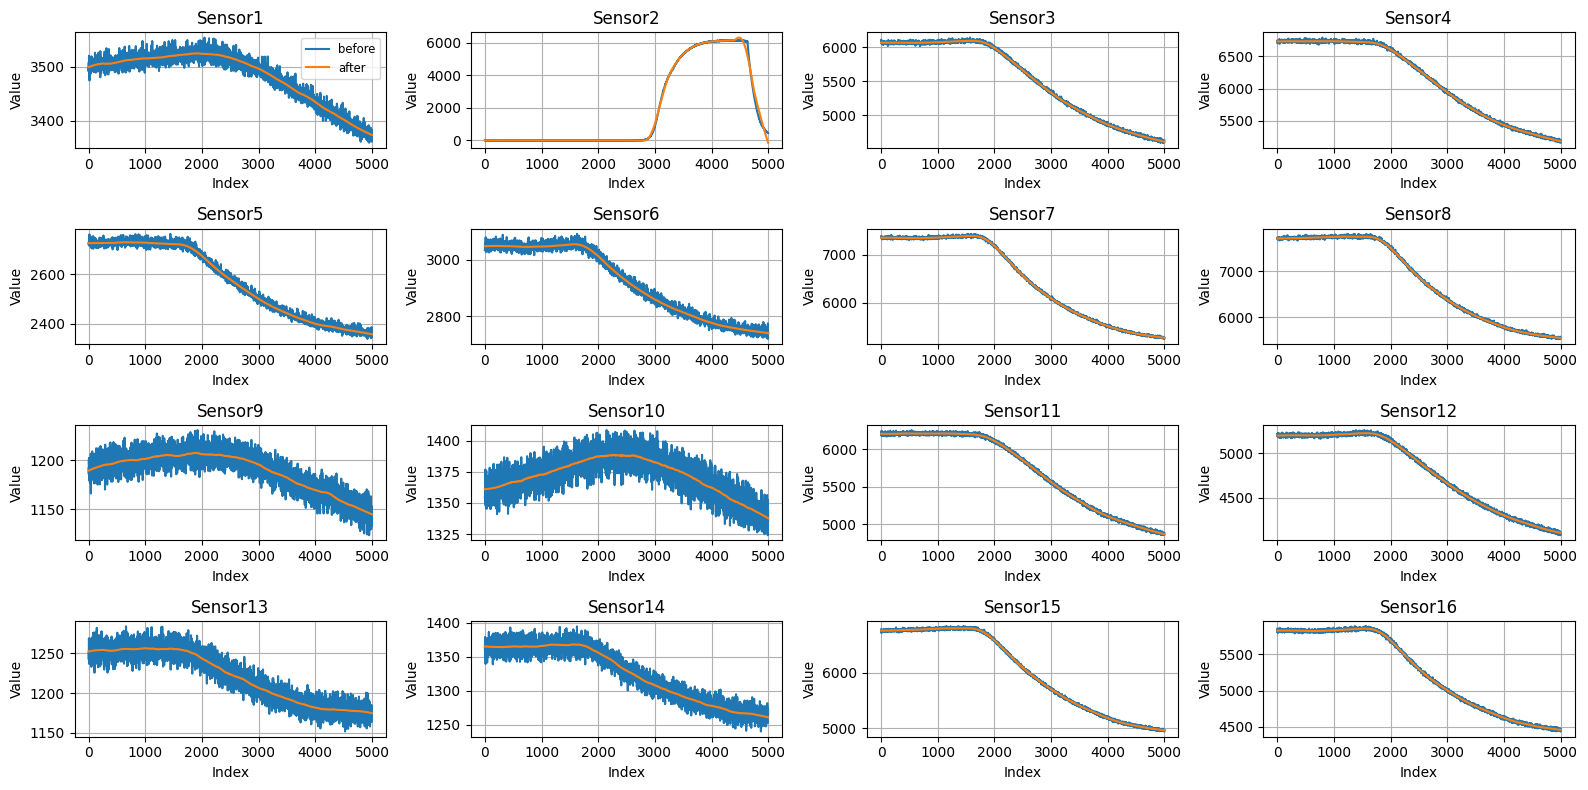

CPU times: user 1.46 s, sys: 18.6 ms, total: 1.47 s
Wall time: 1.5 s


In [8]:
%%time
start_idx = 500000
end_idx = 505000

# Ví dụ sử dụng
sub_EC=EC[start_idx:end_idx].copy()
sub_EC_smooth = sub_EC.copy()
sub_EC_smooth[X_col] = sub_EC[X_col].apply(SG_filter)

# Plot kết quả làm mượt
plot_df_cols([sub_EC, 
              sub_EC_smooth], 
             X_col[:], 
             label_list=['before', 'after'])

## Kalman Filter
chưa áp dụng được

In [9]:
%%time
import numpy as np

def kalman_baseline_sensor(z, Q_base=1e-5, Q_drift=1e-6, R=1e-1, threshold=1, scale_R=100):
    """
    Kalman Filter 2D (baseline + drift) để tách baseline cảm biến khí khỏi tín hiệu có peak.

    Parameters
    ----------
    z : array-like
        Dữ liệu cảm biến 1D theo thời gian
    Q_base : float
        Process noise cho baseline (mức độ trôi nền)
    Q_drift : float
        Process noise cho tốc độ trôi (drift)
    R : float
        Measurement noise
    threshold : float
        Ngưỡng phát hiện peak (khi tín hiệu tăng quá nhanh)
    scale_R : float
        Hệ số tăng R khi gặp peak (giảm tin vào phép đo)
    """
    z = np.asarray(z, dtype=float)
    n = len(z)
    baseline_est = np.zeros_like(z)

    # --- Khởi tạo ---
    x = np.array([z[0], 0.0])  # [baseline, drift]
    P = np.eye(2)

    # Ma trận hệ thống
    F = np.array([[1, 1],
                  [0, 1]])
    H = np.array([[1, 0]])

    Q = np.array([[Q_base, 0],
                  [0, Q_drift]])

    for k in range(1, n):
        # --- Predict ---
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        # --- Điều chỉnh R nếu tín hiệu tăng đột biến ---
        diff = abs(z[k] - x_pred[0])
        Rk = R * scale_R if diff > threshold else R

        # --- Update ---
        y = z[k] - H @ x_pred
        S = H @ P_pred @ H.T + Rk
        K = P_pred @ H.T / S
        x = x_pred + (K.flatten() * y)
        P = (np.eye(2) - K @ H) @ P_pred

        baseline_est[k] = x[0]

    return baseline_est

CPU times: user 5 µs, sys: 0 ns, total: 5 µs
Wall time: 8.11 µs


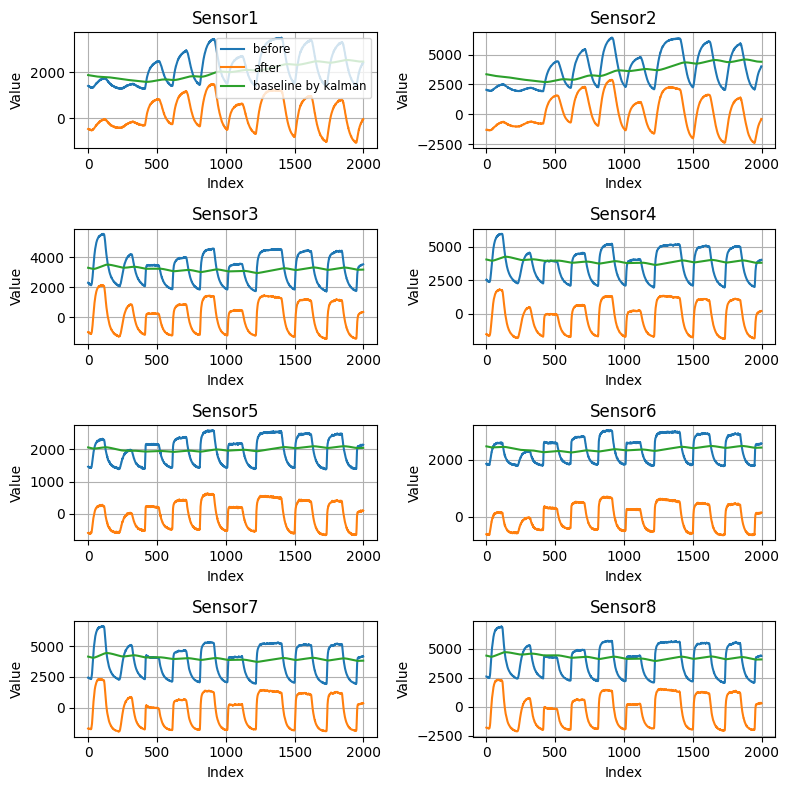

In [10]:
# --- Ước lượng baseline sử dụng Kalman filter---
EC_kal=EC[::100].copy()
baseline_cols = EC_kal[X_col].apply(kalman_baseline_sensor,
                                    Q_base=1e-7, Q_drift=1e-10, R=5e-1, threshold=1, scale_R=200)
EC_kal[X_col] = EC_kal[X_col] - baseline_cols

start_idx = 2000
end_idx = 4000
EC_short=EC[::100].copy()
plot_df_cols([EC_short[start_idx:end_idx], EC_kal[start_idx:end_idx], baseline_cols[start_idx:end_idx]], 
             X_col[:8], 
             label_list=['before', 'after', 'baseline by kalman'])

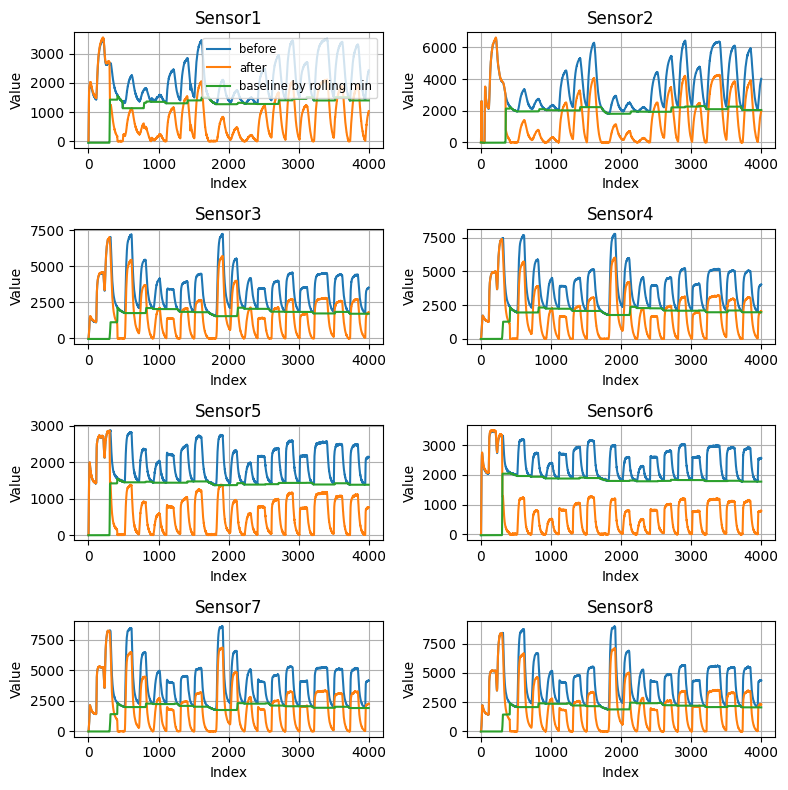

In [11]:
# --- Ước lượng baseline sử dụng rolling min---
EC_kal=EC[::100].copy()
rolling_min = EC_kal[X_col].rolling(window=300, center=False, min_periods=1).min()
EC_kal[X_col] = EC_kal[X_col] - rolling_min

start_idx = 0
end_idx = 4000
EC_short=EC[::100].copy()
plot_df_cols([EC_short[start_idx:end_idx], EC_kal[start_idx:end_idx], rolling_min[start_idx:end_idx]], 
             X_col[:8], 
             label_list=['before', 'after', 'baseline by rolling min'])


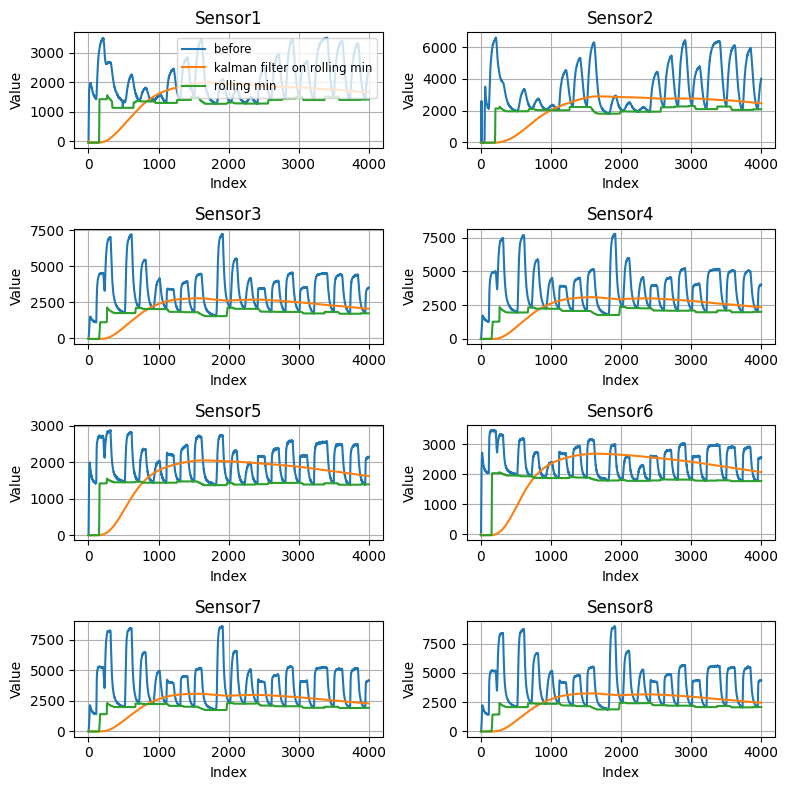

CPU times: user 19.1 s, sys: 317 ms, total: 19.4 s
Wall time: 19.1 s


In [12]:
%%time
# --- Ước lượng baseline sử dụng rolling min---
EC_kal=EC[::100].copy()
rolling_min = EC_kal[X_col].rolling(window=300, center=True, min_periods=1).min()
EC_kal[X_col] = rolling_min.apply(kalman_baseline_sensor,
                                    Q_base=1e-7, Q_drift=1e-10, R=5e-1, threshold=1, scale_R=200)

start_idx = 0
end_idx = 4000
EC_short=EC[::100].copy()
plot_df_cols([EC_short[start_idx:end_idx], EC_kal[start_idx:end_idx], rolling_min[start_idx:end_idx]], 
             X_col[:8], 
             label_list=['before', 'kalman filter on rolling min', 'rolling min'])

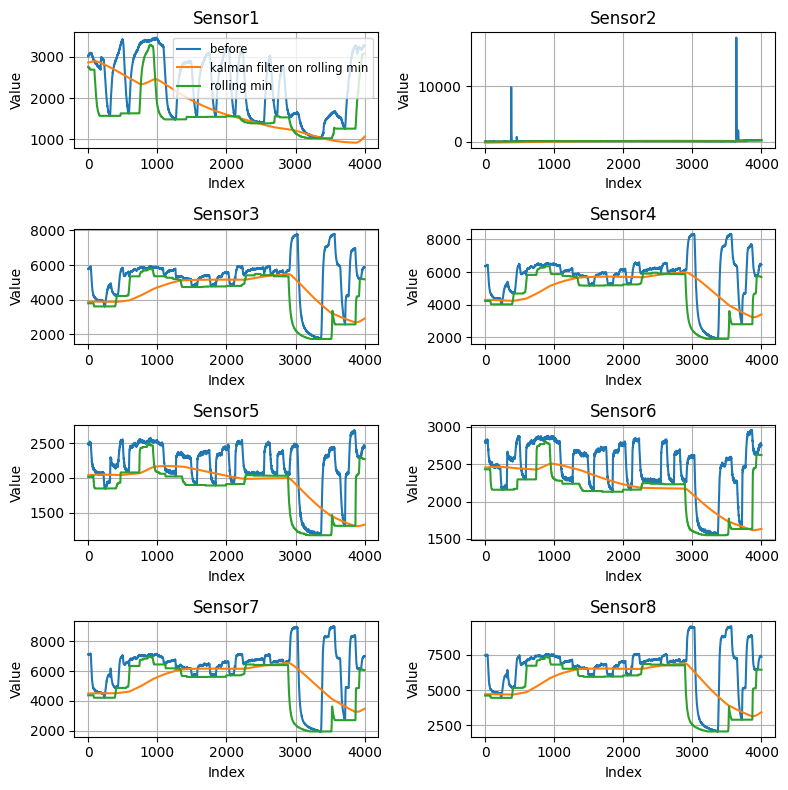

In [13]:
start_idx = 8000
end_idx = 12000
EC_short=EC[::100].copy()
plot_df_cols([EC_short[start_idx:end_idx], EC_kal[start_idx:end_idx], rolling_min[start_idx:end_idx]], 
             X_col[:8], 
             label_list=['before', 'kalman filter on rolling min', 'rolling min'])

## Preprocessing
- Bỏ những dòng null/ bị thiếu
- Bỏ những dòng không có khí nào
- Chia tách các lần đo/ các instance bằng cách gán cột 'Label'
- Bỏ những lần đo ngắn hơn 64s

In [14]:
# Tìm null -> không có
missing_values = EC.isnull().any(axis=1)
print("Các dòng dữ liệu lỗi:")
print(EC[missing_values])

Các dòng dữ liệu lỗi:
Empty DataFrame
Columns: [Time (seconds), CO2 conc (ppm), Ethylene conc (ppm), Sensor1, Sensor2, Sensor3, Sensor4, Sensor5, Sensor6, Sensor7, Sensor8, Sensor9, Sensor10, Sensor11, Sensor12, Sensor13, Sensor14, Sensor15, Sensor16]
Index: []


In [15]:
# Bỏ những dòng không có khí nào
def remove_empty_conc(df, filter_cols):
    # loại bỏ các hàng mà tất cả các cột filter đều bằng 0
    #mask_all_zero = (df[filter_cols] == 0).all(axis=1)
    #df_out = df.loc[~mask_all_zero]
    #df_out = df_out.reset_index(drop=True)
    df_out=df
    print(f"Previous remove empty shape: {df.shape}")
    print(f"After remove empty shape: {df_out.shape}")
    return df_out
    
# Ví dụ sử dụng
# EC2 = remove_empty_conc(EC_smooth, ["CO2 conc (ppm)", "Ethylene conc (ppm)"])
# EC2.head()

In [16]:
# Gán nhãn Label để đánh dấu chia các lần đo, các instance
# mỗi lần khí thay đổi là một instance mới
def label_data(df):
    df['Label'] = df.groupby(['CO2 conc (ppm)', 'Ethylene conc (ppm)']).ngroup() + 1
    df['Label'] = (df['Label'] != df['Label'].shift()).cumsum()
    df = df[['Label'] + [col for col in df.columns if col != 'Label']]
    return df

Drop total of 34 labels: [37, 38, 46, 54, 62, 71, 72, 78, 80, 82, 90, 100, 113, 120, 121, 178, 186, 187, 196, 203, 204, 229, 282, 283, 284, 309, 318, 319, 321, 322, 323, 324, 333, 345]
Initial Label col have 373 values
Later Label col have 339 values


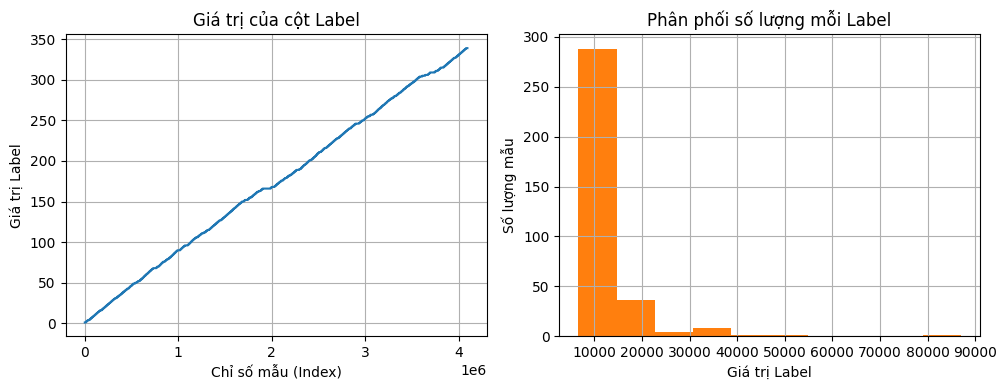

In [17]:
def drop_label_few(df, label_col, count_thres):
    # Drop Labels has fewer than 6400 rows (ngắn hơn 64s)
    df = label_data(df)
    
    grouped = df.groupby('Label')
    labels_to_drop = []  
    
    # Iterate over each group
    for label, group in grouped:
        # Check if the group has fewer than 64 rows
        if len(group) < 6400:
            labels_to_drop.append(label)
            
    # Drop the rows with labels in labels_to_drop
    df_out = df[~df['Label'].isin(labels_to_drop)].reset_index(drop=True)
    print(f'Drop total of {len(labels_to_drop)} labels: {labels_to_drop}')
    
    # Relabeling
    df_out = label_data(df_out)
    df_out = df_out.reset_index(drop=True)
                               
    print(f"Initial Label col have {len(df['Label'].unique())} values")
    print(f"Later Label col have {len(df_out['Label'].unique())} values")
    return df_out

# Ví dụ dùng
EC3 = drop_label_few(EC_smooth, label_col="Label", count_thres=6400)
grouped = EC3.groupby('Label').count()['Time (seconds)']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# --- Plot 1: Giá trị cột Label theo chỉ số ---
axes[0].plot(EC3['Label'], color='tab:blue')
axes[0].set_title("Giá trị của cột Label")
axes[0].set_xlabel("Chỉ số mẫu (Index)")
axes[0].set_ylabel("Giá trị Label")
axes[0].grid(True)

# --- Plot 2: Phân phối độ dài của mỗi Label ---
grouped.hist(ax=axes[1], color='tab:orange')
axes[1].set_title("Phân phối số lượng mỗi Label")
axes[1].set_xlabel("Giá trị Label")
axes[1].set_ylabel("Số lượng mẫu")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Split into 5 splits
- Tách data thành 5 phần nhỏ theo các lần đo (label)
- Chuẩn hóa (Normalization) từng phần bằng Min Max Scaler
- Các phần nhỏ không chứa label nào trùng nhau, có kich cỡ bằng nhau, được tách ngẫu nhiên

In [18]:
import random

def split_into_k_chunks(df, k, norm_cols):
    """
        Tách data thành 5 phần nhỏ theo các lần đo (label)
        Chuẩn hóa (Normalization) từng phần bằng Min Max Scaler
        Các phần nhỏ không chứa label nào trùng nhau, có kich cỡ bằng nhau, được tách ngẫu nhiên
    """
    numbers = list(range(1, len(df['Label'].unique())+1))
    random.shuffle(numbers)
    
    # Chia thành 5 list con xấp xỉ bằng nhau
    k = 5
    chunk_size = len(numbers) // k
    remainder = len(numbers) % k
    
    subdatasets = []
    scaler = MinMaxScaler()
    
    start = 0
    for i in range(k):
        # Tìm sublist của label
        end = start + chunk_size + (1 if i < remainder else 0)
        sublist = numbers[start:end]
        start = end
    
        # Lọc ra dữ liệu của label trong sublist
        subset = df[df['Label'].isin(sublist)].copy().reset_index(drop=True)
        
        # Normalization - chuẩn hóa trên từng tập subdata/ tập split nhỏ    
        subset[norm_cols] = pd.DataFrame(scaler.fit_transform(subset[norm_cols]), columns=norm_cols)
    
        subdatasets.append(subset)
        print(f"Subdataset {i+1} ({len(sublist)} labels): {len(subset)} rows")
    return subdatasets

# Ví dụ sử dụng
# Tách dataframe thành 5 subdatasets tương ứng và Chuẩn hóa
subdatasets = split_into_k_chunks(EC3, k=5, norm_cols=X_col)

Subdataset 1 (68 labels): 822191 rows
Subdataset 2 (68 labels): 873001 rows
Subdataset 3 (68 labels): 798301 rows
Subdataset 4 (68 labels): 817873 rows
Subdataset 5 (67 labels): 781896 rows


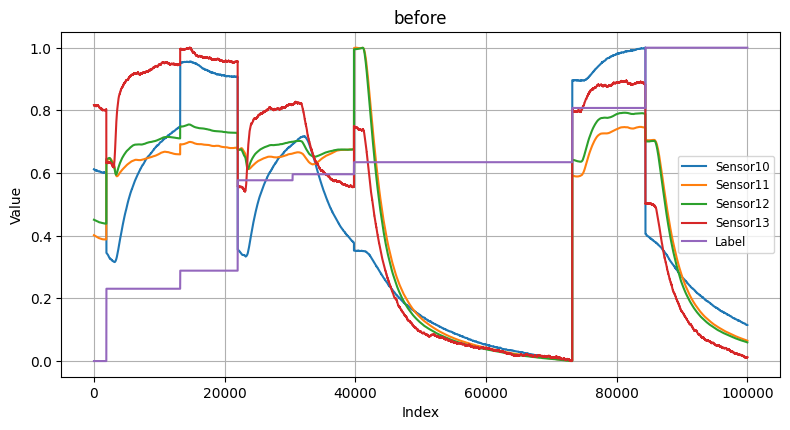

In [19]:
plot_dfs([subdatasets[3][200000:300000]],
             X_col[9:13]+['Label'], 
             label_list=['before', 'after'])

## Augment 
**Thực hiện trên từng phần trong 5 phần:**
- Tăng cường bằng các bước nhảy lệch
- Chuyển sang cỡ ảnh 64x64 rồi lưu
- Mỗi lần đo/ instance/ group/ 1 ảnh gốc, sẽ được tăng cường thành 5 ảnh, lệch nhau step_size dòng

**Ví dụ:** 
- step_size = 10 => sẽ lấy bắt đầu từ index 0, 10, 20, 30, 40
- step_size = 20 => sẽ lấy bắt đầu từ index 0, 20, 40, 60, 80
- step_size = 25 => sẽ lấy bắt đầu từ index 0, 25, 50, 75, 100 (ảnh lấy từ 0 và 100 sẽ gần như trùng nhau)

**Mỗi ảnh sẽ gồm:**
- 64 cột (16 cột cảm biến x4),
- 64 dòng, mỗi dòng có Time(seconds) cách nhau 1 giây, tức cách nhau 100 dòng trong data gốc

In [20]:
%%time
def save_image(image_array, img_path):
    """save image as grayscale."""
    # Normalize image to range (0, 255)
    image = (image_array * 255).astype(np.uint8)
    # Save img
    image = Image.fromarray(image).convert("L")
    image.save(img_path)

def generate_images(subdatasets, X_col, y_col, step_size=1,
                    num_augments=1, out_dir="unaugmented"):
    """
    Generate and save images (augmented or not) from subdatasets.
    Args:
        subdatasets: list of DataFrames
        X_col: columns used for image creation
        y_col: label-related columns
        step_size: number of rows to shift when augmenting
        num_augments: number of augmentations per label (1 for unaugment)
        out_dir: base output directory
    # This notebook originally belong to huong.nguyenthu4@hust.edu.vn 
    Returns:
        image_data_df: DataFrame containing label + image info
    """
    image_data = []

    for i, subdata in enumerate(subdatasets):
        folder_name = f"{out_dir}/split{i+1}"
        os.makedirs(folder_name, exist_ok=True)
        grouped = subdata.groupby("Label")

        for label, group in grouped:
            for j in range(num_augments):
                start = j * step_size
                img_name = (
                    f"img_label{label}_aug{j}.png" if num_augments > 1
                    else f"img_label{label}.png"
                )
                img_path = f"{folder_name}/{img_name}"

                # Get data for one image
                image = group.iloc[start:(64*100+start):100][X_col].copy()
                # Scale up 4 times (convert to 64x64 size) 
                image = np.repeat(image, 4, axis=1)  # scale width 100→400
                # Scale up 2 times each dim (to 128x128)
                image = np.repeat(np.repeat(image, 2, axis=0), 2, axis=1)

                # # Add few noise to generalize data
                # noise = np.random.normal(0, 0.005, image.shape)
                # image = np.clip(image + noise, 0, 1)

                save_image(image, img_path)
                                    
                # Save image info
                row = np.append(group.head(1)[y_col].values[0], [img_name, i+1])
                image_data.append(row)

    # Save CSV info
    image_data_df = pd.DataFrame(image_data, columns=np.append(y_col, ["image_name", "split_number"]))
    csv_path = f"{out_dir}/image_labels.csv"
    image_data_df.to_csv(csv_path, index=False)
    print(f"Saved: {csv_path}")
    return image_data_df

# ví dụ sử dụng 
df = generate_images(subdatasets, X_col, y_col,
               step_size=20,
               num_augments=5,
               out_dir="augmented")

Saved: augmented/image_labels.csv
CPU times: user 2.74 s, sys: 185 ms, total: 2.93 s
Wall time: 2.93 s


# Toàn bộ quy trình 
(xử lý và lọc nhiễu, tách thành ảnh, tăng cường dữ liệu và lưu lại)

In [21]:
%%time
def complete_pipeline(df_ori, X_col, y_col, chunk_numb = 5, aug_step_size = 10, aug_times = 5):
    df = df_ori.copy()
    
    # SG filter smooth
    df[X_col] = df[X_col].apply(SG_filter)

    # Filter out rows with no gas or too few data (<64s)
    # df = remove_empty_conc(df, ["CO2 conc (ppm)", "Ethylene conc (ppm)"])
    df = drop_label_few(df, label_col="Label", count_thres=6400)

    # Split data into chunks
    subdatasets = split_into_k_chunks(df, k=chunk_numb, norm_cols=X_col)
    
    # Augment each chunk, normalize, cut into images, and save
    augmented_df = generate_images(subdatasets, X_col, y_col,
                                   step_size=aug_step_size,
                                   num_augments=aug_times,
                                   out_dir="augmented")
    print(augmented_df.groupby('split_number').count())

    # Normalize, cut into images, and save
    unaugmented_df = generate_images(subdatasets, X_col, y_col,
                                     step_size=aug_step_size,
                                     num_augments=1,
                                     out_dir="unaugment")
    print(unaugmented_df.groupby('split_number').count())

# Xử lý dữ liệu
complete_pipeline(EC, X_col, y_col)

Drop total of 34 labels: [37, 38, 46, 54, 62, 71, 72, 78, 80, 82, 90, 100, 113, 120, 121, 178, 186, 187, 196, 203, 204, 229, 282, 283, 284, 309, 318, 319, 321, 322, 323, 324, 333, 345]
Initial Label col have 373 values
Later Label col have 339 values
Subdataset 1 (68 labels): 814986 rows
Subdataset 2 (68 labels): 780131 rows
Subdataset 3 (68 labels): 828088 rows
Subdataset 4 (68 labels): 753988 rows
Subdataset 5 (67 labels): 916069 rows
Saved: augmented/image_labels.csv
              CO2 conc (ppm)  Ethylene conc (ppm)  image_name
split_number                                                 
1                        340                  340         340
2                        340                  340         340
3                        340                  340         340
4                        340                  340         340
5                        335                  335         335
Saved: unaugment/image_labels.csv
              CO2 conc (ppm)  Ethylene conc (ppm)  image_

# Ví dụ đọc data thành tập train và test

In [22]:
# Đọc file csv chứa thông tin về ảnh (nồng độ, tên ảnh, split tương ứng)
folder = "augmented" 
# folder = "unaugment" 
df = pd.read_csv(f'/kaggle/working/{folder}/image_labels.csv')
df.head()

,CO2 conc (ppm),Ethylene conc (ppm),image_name,split_number
0,0.0,0.0,img_label1_aug0.png,1
1,0.0,0.0,img_label1_aug1.png,1
2,0.0,0.0,img_label1_aug2.png,1
3,0.0,0.0,img_label1_aug3.png,1
4,0.0,0.0,img_label1_aug4.png,1


In [23]:
# Hàm đọc ảnh từ những split cho vào
# Trả về ảnh và nhãn tương ứng dưới dạng: ma trận [số ảnh, 64, 64, 1] và ma trận [số ảnh,2]
def read_image(path):
    """
    Đọc ảnh grayscale và trả về numpy array (giá trị 0–1)
    """
    img = Image.open(path).convert('L')
    arr = np.array(img).astype(np.float32) / 255.0
    return arr

def read_img_from_splits(df, split_list):
    # Chỉ lấy các dòng thuộc list split đã chọn
    df_part = df[df['split_number'].isin(split_list)]
    images = []

    # Lặp qua từng hàng trong dataframe để đọc ảnh và lấy nhãn tương ứng 
    for index, row in df_part.iterrows():
        img_path = folder + '/split' + str(row['split_number']) + '/' + str(row['image_name'])
        img = read_image(img_path)
        # img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Đọc ảnh xám
        # img = np.array(img).astype('float32') / 255.0  # Chuẩn hóa dữ liệu ảnh
        images.append(img)

    # Chuyển đổi danh sách thành numpy arrays
    df_part.loc[:,["Image"]] = images
    images = np.array(images)
    
    return images, df_part[['CO2 conc (ppm)', 'Ethylene conc (ppm)']], df_part

In [24]:
# Xác định tập train và test sẽ gồm những split nào trong 5 split
# This notebook originally belong to huong.nguyenthu4@hust.edu.vn
# Chỉ cần điền những split trong tập test, tập train sẽ tự bao gồm những split còn lại
# VD: split_test = [3,5] thì split_train = [1,2,4]
split_test = [4, 2]

split_train = [i for i in range(1,6) if i not in split_test] 
print("Những split sẽ thuộc tập train là: ", split_train)
print("Những split sẽ thuộc tập test là: ", split_test)

Những split sẽ thuộc tập train là:  [1, 3, 5]
Những split sẽ thuộc tập test là:  [4, 2]


In [25]:
%%time
# Sử dụng hàm đọc ảnh từ thư mục các split tương ứng
X_train, y_train, df_train = read_img_from_splits(df, split_train)
X_test, y_test, df_test = read_img_from_splits(df, split_test)

print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')
df_train

X_train shape: (1015, 128, 128)
y_train shape: (1015, 2)
X_test shape: (680, 128, 128)
y_test shape: (680, 2)
CPU times: user 445 ms, sys: 77.1 ms, total: 522 ms
Wall time: 524 ms


,CO2 conc (ppm),Ethylene conc (ppm),image_name,split_number,Image
0,0.00,0.0,img_label1_aug0.png,1,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
1,0.00,0.0,img_label1_aug1.png,1,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
2,0.00,0.0,img_label1_aug2.png,1,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
3,0.00,0.0,img_label1_aug3.png,1,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
4,0.00,0.0,img_label1_aug4.png,1,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.00..."
...,...,...,...,...,...
1690,333.33,0.0,img_label336_aug0.png,5,"[[0.11764706, 0.11764706, 0.11764706, 0.117647..."
1691,333.33,0.0,img_label336_aug1.png,5,"[[0.11764706, 0.11764706, 0.11764706, 0.117647..."
1692,333.33,0.0,img_label336_aug2.png,5,"[[0.11764706, 0.11764706, 0.11764706, 0.117647..."
1693,333.33,0.0,img_label336_aug3.png,5,"[[0.11764706, 0.11764706, 0.11764706, 0.117647..."


# Tạo bất thường

## Các loại bất thường

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import cv2

# --- Các hàm tạo bất thường cơ bản ---
def add_noise(img, severity=0.3):
    """
    Nhiễu Gaussian nhưng khác nhau theo từng sensor (cột)
    """
    H, W = img.shape[:2]
    
    # mỗi sensor có noise khác nhau
    sensor_std = np.random.uniform(0.01, severity, W)
    noise = np.random.randn(H, W) * sensor_std
    
    return np.clip(img + noise, 0, 1)
def add_signal_drift(img, direction='vertical', severity=0.3):
    """
    Drift theo thời gian (chiều H) – giống aging cảm biến
    """
    H, W = img.shape[:2]
    
    t = np.linspace(0, 1, H)
    
    # drift không tuyến tính (thực tế hơn)
    drift = (t ** 1.5) * severity  
    drift = drift[:, np.newaxis]
    
    return np.clip(img + drift, 0, 1)
def add_random_patch(img, size_ratio=0.1, severity=0.8):
    """
    Một vùng nhỏ bị nhiễu mạnh (sensor lỗi cục bộ hoặc nhiễu môi trường)
    """
    H, W = img.shape[:2]
    
    patch_H = int(H * size_ratio)
    patch_W = int(W * size_ratio)
    
    y = np.random.randint(0, H - patch_H)
    x = np.random.randint(0, W - patch_W)
    
    direction = np.random.choice([-1, 1])
    
    img_new = img.copy()
    img_new[y:y+patch_H, x:x+patch_W] += severity * direction
    
    return np.clip(img_new, 0, 1)
def add_abrupt_change(img, severity=0.4):
    """
    Tín hiệu thay đổi đột ngột (ví dụ: thay đổi khí hoặc lỗi hệ thống)
    """
    H, W = img.shape[:2]
    
    cut = np.random.randint(H // 4, 3 * H // 4)
    direction = np.random.choice([-1, 1])
    
    magnitude = severity * direction
    
    # tạo transition mượt
    transition_len = int(H * 0.1)
    ramp = np.zeros(H)
    
    smooth = np.linspace(0, magnitude, transition_len)
    
    ramp[cut:cut+transition_len] = smooth[:max(0, H - cut)]
    
    if cut + transition_len < H:
        ramp[cut+transition_len:] = magnitude
    
    ramp = ramp[:, np.newaxis]
    
    return np.clip(img + ramp, 0, 1)
def add_sensor_failure(img, severity=0.1):
    H, W = img.shape[:2]
    
    num_fail = int(W * severity)  # dùng severity thay ratio
    fail_idx = np.random.choice(W, num_fail, replace=False)
    
    img_new = img.copy()
    
    for i in fail_idx:
        mode = np.random.choice(['dead', 'stuck'])
        
        if mode == 'dead':
            img_new[:, i] = 0
        else:
            img_new[:, i] = img_new[0, i]
    
    return np.clip(img_new, 0, 1)

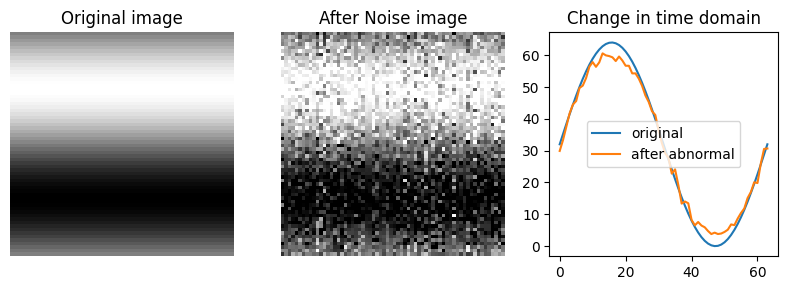

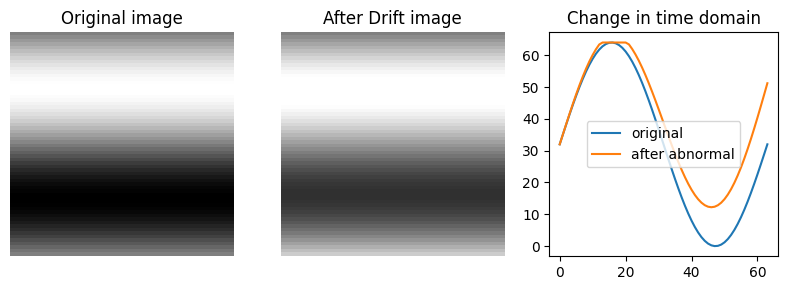

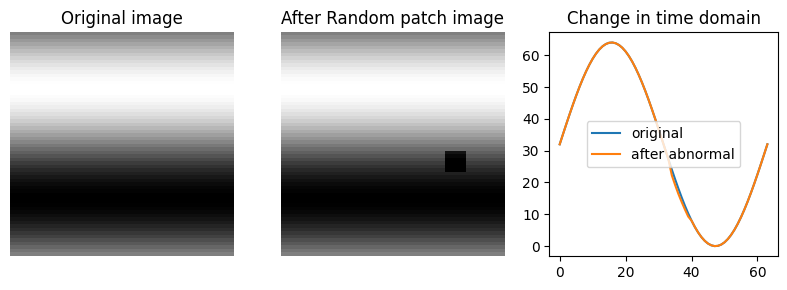

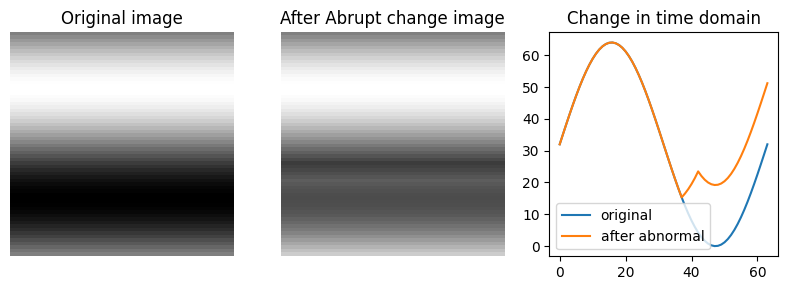

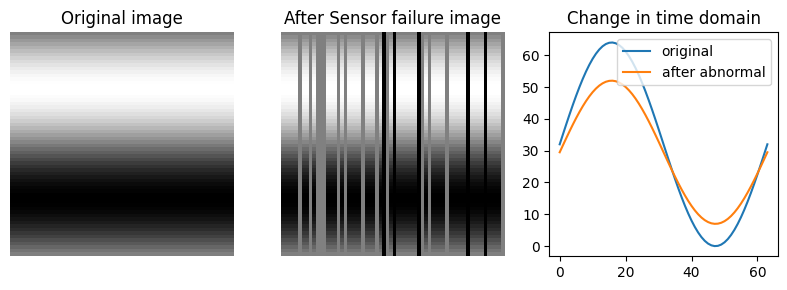

In [28]:
def visualize_abnormal_change(ab_func, ab_name, severity, scale=True):
    vmin=0 if scale else None
    vmax=1 if scale else None
    
    # ảnh
    x = np.linspace(0, 2*np.pi, 64)
    sin_wave = (np.sin(x) + 1) / 2
    img = np.tile(sin_wave[:, None], (1, 64))
    
    img_ab = ab_func(img, severity=severity)

    # visualize
    plt.figure(figsize=(8,3))
    if scale:
        plt.subplot(1,3,1)
        plt.imshow(img, cmap='gray', vmin=vmin, vmax=vmax); plt.title("Original image"); plt.axis("off")
    plt.subplot(1,3,2)
    plt.imshow(img_ab, cmap='gray', vmin=vmin, vmax=vmax); plt.title(f"After {ab_name} image"); plt.axis("off")
    
    plt.subplot(1,3,3)
    plt.plot(img.sum(axis=1), label='original')
    plt.plot(img_ab.sum(axis=1), label='after abnormal'); plt.title("Change in time domain")

    plt.tight_layout()
    plt.legend()
    plt.show()

severity = 0.3
scale = True # Scale lại ảnh về khoảng 0 1 để thấy rõ sự thay đổi theo severity
visualize_abnormal_change(add_noise, "Noise", severity, scale=scale)
visualize_abnormal_change(add_signal_drift, "Drift", severity, scale=scale)
visualize_abnormal_change(add_random_patch, "Random patch", severity, scale=scale)
visualize_abnormal_change(add_abrupt_change, "Abrupt change", severity, scale=scale)
visualize_abnormal_change(add_sensor_failure, "Sensor failure", severity, scale=scale)

## Áp bất thường lên ảnh

In [29]:
def apply_abnormal(img, label, severity_range=(0.5), show=True):
    """
    Mỗi abnormal được áp với severity ngẫu nhiên.
    Trả về:
        img_ab
        severity_dict
        dominant_abnormal
    """

    img_ab = img.copy()

    methods = {
        "Noise": lambda x, s: add_noise(x, s),
        "Signal Drift": lambda x, s: add_signal_drift(
            x,
            random.choice(['horizontal', 'vertical']),
            s
        ),
        "Random Patch": lambda x, s: add_random_patch(
            x,
            size_ratio=0.1 + s * 0.1,
            severity=s
        ),
        "Abrupt Change": lambda x, s: add_abrupt_change(x, s),    
        "Sensor Failure": lambda x, s: add_sensor_failure(
             x,
             severity=s
         ),
    }

    chosen_methods = random.sample(
        list(methods.items()),
        random.randint(1, len(methods))
    )

    severity_dict = {}

    for name, fn in chosen_methods:

        severity = np.random.uniform(
            severity_range[0],
            severity_range[1]
        )

        severity_dict[name] = float(severity)

        img_ab = fn(img_ab, severity)
        img_ab = np.clip(img_ab, 0, 1)

    dominant_abnormal = max(
        severity_dict,
        key=severity_dict.get
    )

    if show:

        fig, axes = plt.subplots(1, 2, figsize=(10, 4))

        gas_info = " | ".join(
            [f"{gas}: {float(value):.2f}"
             for gas, value in label.items()]
        )

        axes[0].imshow(
            img.squeeze(),
            cmap='gray',
            vmin=0,
            vmax=1
        )
        axes[0].set_title(f"Original\n{gas_info}")
        axes[0].axis("off")

        severity_text = "\n".join(
            [
                f"{k}: {v:.3f}"
                for k, v in severity_dict.items()
            ]
        )

        axes[1].imshow(
            img_ab.squeeze(),
            cmap='gray',
            vmin=0,
            vmax=1
        )

        axes[1].set_title(
            f"Dominant: {dominant_abnormal}\n{severity_text}"
        )

        axes[1].axis("off")

        plt.tight_layout()
        plt.show()

    return img_ab, severity_dict, dominant_abnormal
    
# --- Hàm chính ---
def generate_anomaly_from_df(df, 
                             anomaly_ratio=0.15, 
                             random_seed=42):
    """
    Tạo bất thường từ DataFrame chứa ảnh gốc.
    This notebook originally belong to huong.nguyenthu4@hust.edu.vn
    
    Parameters:
    -----------
    df : pd.DataFrame
        DataFrame chứa ít nhất 2 cột:
            - 'Image': numpy array (H, W)
            - 'image_name': string
    anomaly_ratio : float
        Tỉ lệ số ảnh sẽ được chọn để tạo bất thường (0–1)
    random_seed : int | None
        Đặt seed để tái lập kết quả

    Returns:
    --------
    df_out : pd.DataFrame
        DataFrame chứa cả ảnh bình thường và bất thường,
        có thêm cột 'is_normal' (1=bình thường, 0=bất thường),
        và ảnh bất thường có tên thêm "_ab" vào trước ".png".
    """
    if random_seed is not None:
        np.random.seed(random_seed)
        random.seed(random_seed)

    df = df.copy()

    # Đánh nhãn ảnh gốc
    df['is_normal'] = 1
    df['severity'] = 0

    # Số ảnh bất thường cần tạo
    n_anomalies = int(len(df) * anomaly_ratio)
    chosen_idx = random.sample(range(len(df)), n_anomalies)

    anomaly_rows = []

    # Duyệt từng ảnh được chọn để tạo bất thường
    for idx in chosen_idx:
    
        row = df.iloc[idx]
    
        img = row['Image']
        label = row[y_col]
    
        show = np.random.uniform() < 0.01
    
        img_ab, severity_dict, dominant_abnormal = apply_abnormal(
            img,
            label=label,
            severity_range=(0.1,0.20, 0.25, 0.35),
            show=show
        )
    
        new_row = row.copy()
    
        new_row['Image'] = img_ab
    
        new_row['image_name'] = (
            row['image_name']
            .replace('.png', '_ab.png')
        )
    
        new_row['is_normal'] = 0
    
        # abnormal mạnh nhất
        new_row['dominant_abnormal'] = dominant_abnormal
    
        # severity của abnormal mạnh nhất
        new_row['severity'] = severity_dict[dominant_abnormal]
    
        # lưu toàn bộ severity
        new_row['abnormal_detail'] = severity_dict
    
        anomaly_rows.append(new_row)
        
    # Ghép và sắp xếp
    df_ab = pd.DataFrame(anomaly_rows)
    df_out = pd.concat([df, df_ab], ignore_index=True)
    df_out = df_out.sort_values(by='image_name').reset_index(drop=True)

    return df_out

Split 1: loaded 340 normal images. 

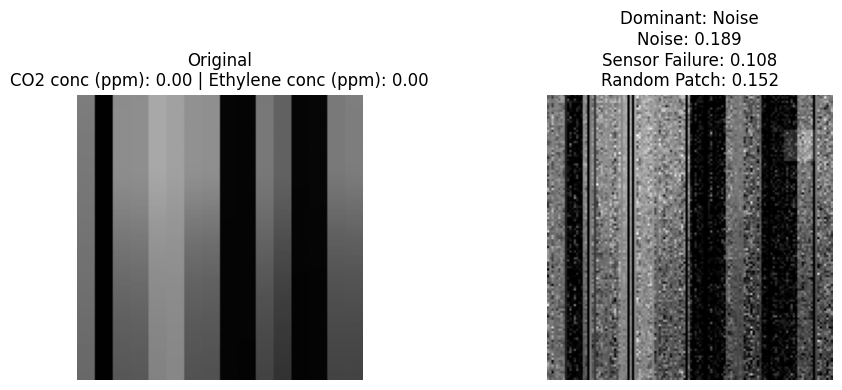

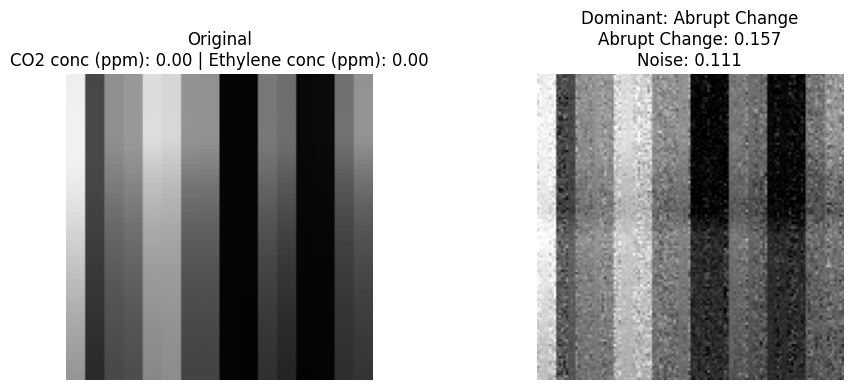

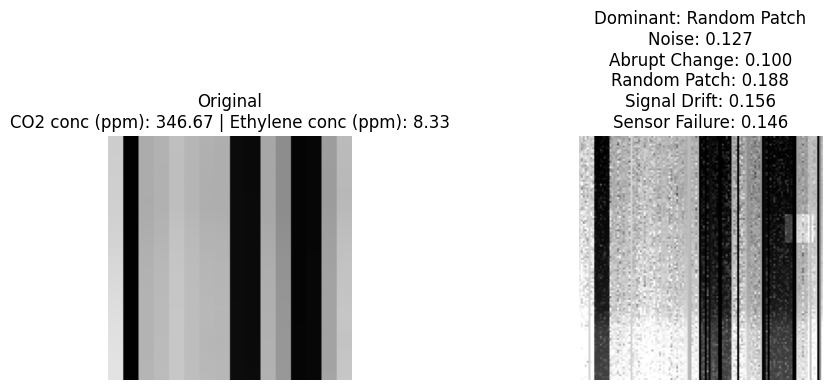

Generated anomalies → total 680 images
Split 2: loaded 340 normal images. 

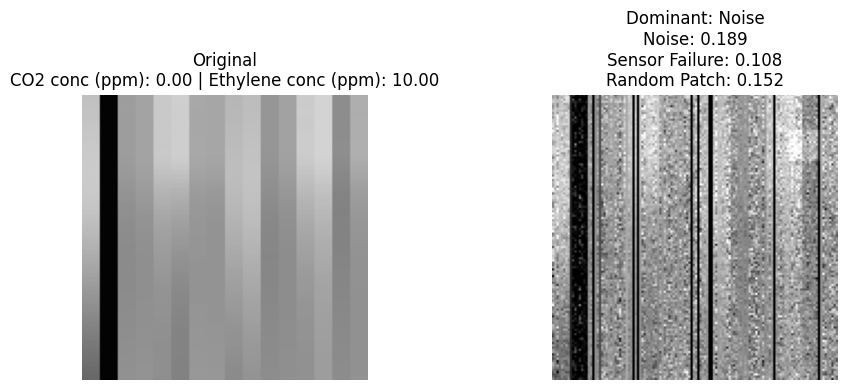

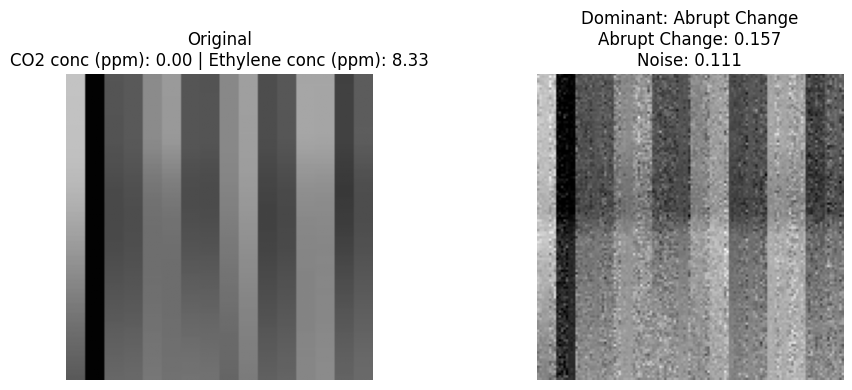

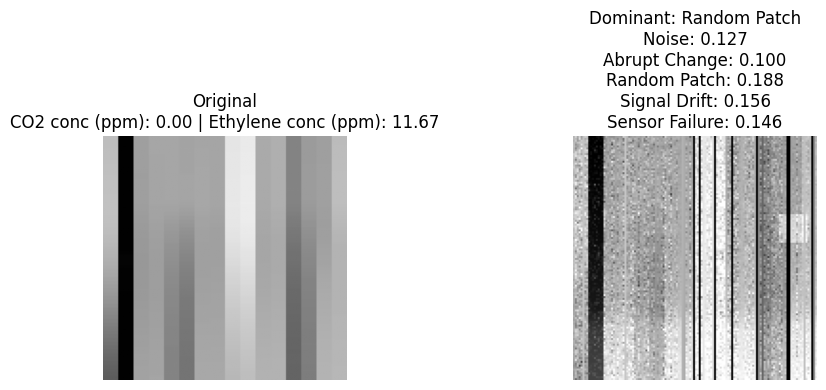

Generated anomalies → total 680 images
Split 3: loaded 340 normal images. 

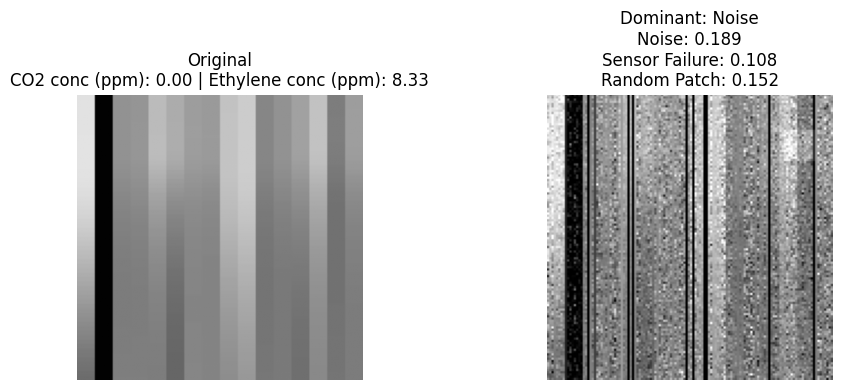

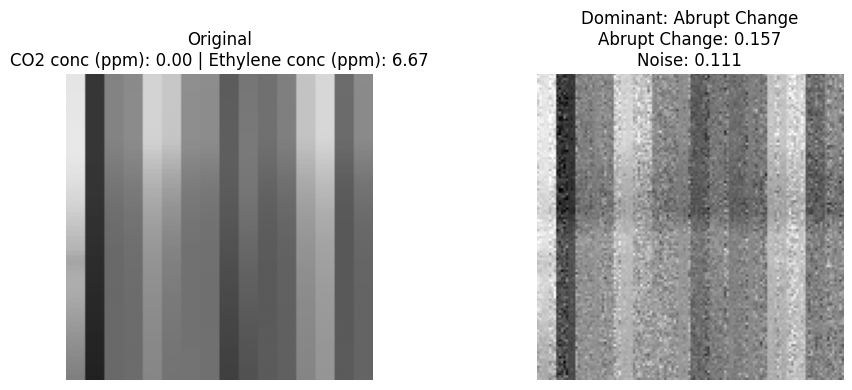

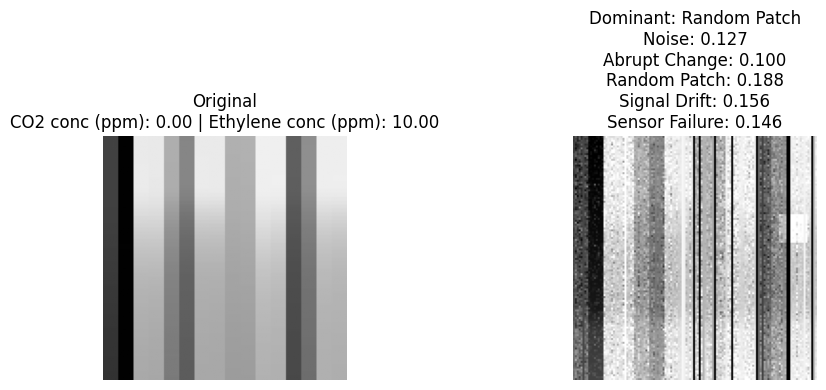

Generated anomalies → total 680 images
Split 4: loaded 340 normal images. 

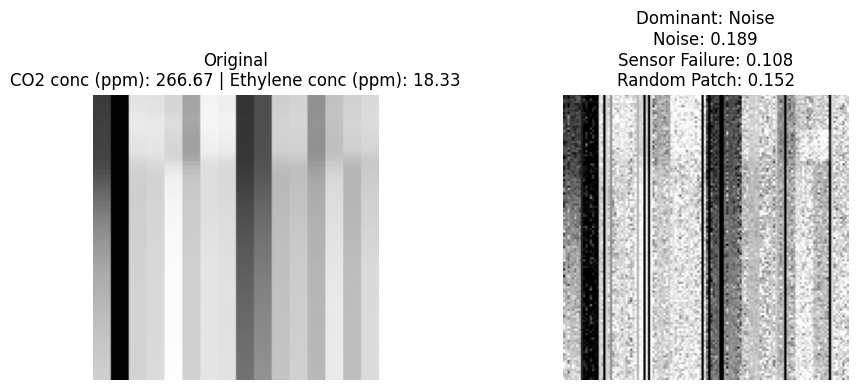

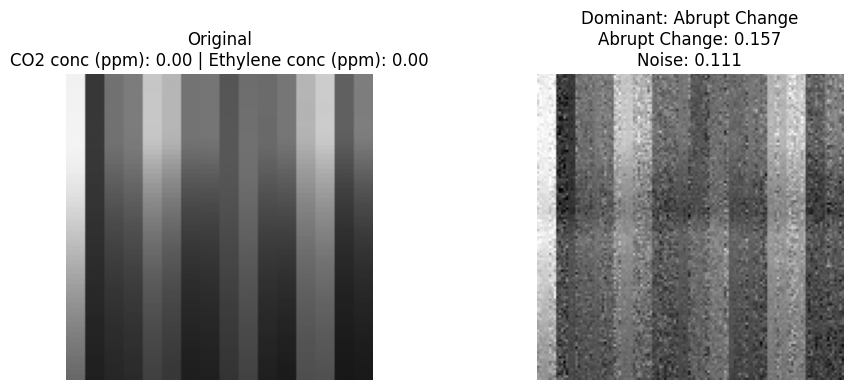

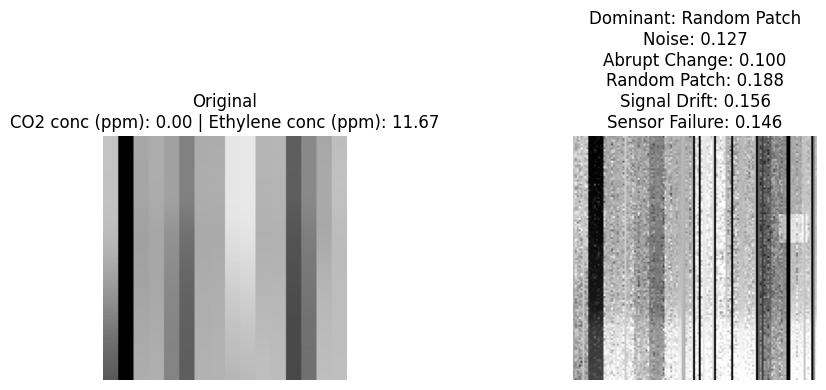

Generated anomalies → total 680 images
Split 5: loaded 335 normal images. 

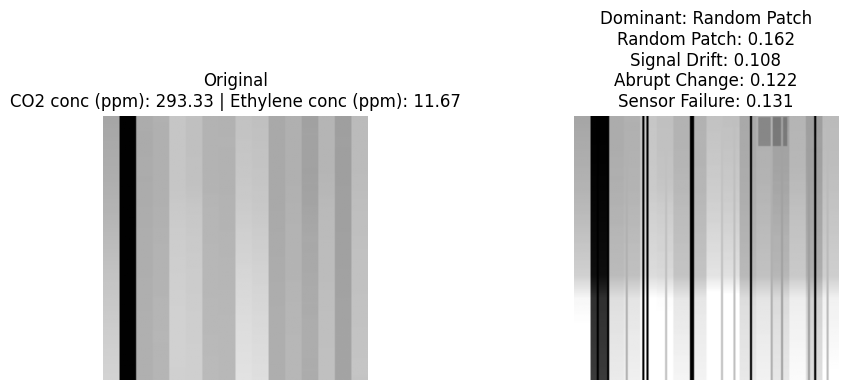

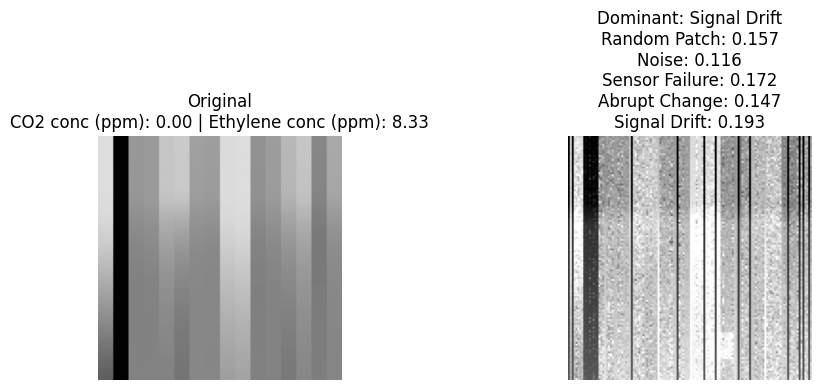

Generated anomalies → total 670 images
✅ Done: Generated augmented abnormal dataset.


,CO2 conc (ppm),Ethylene conc (ppm),image_name,split_number,is_normal,severity,dominant_abnormal,abnormal_detail
0,306.67,10.0,img_label103_aug0.png,1,1,0.000000,NaN,NaN
1,306.67,10.0,img_label103_aug0_ab.png,1,0,0.179488,Abrupt Change,"{'Sensor Failure': 0.16159916648790412, 'Rando..."
2,306.67,10.0,img_label103_aug1.png,1,1,0.000000,NaN,NaN
3,306.67,10.0,img_label103_aug1_ab.png,1,0,0.153724,Random Patch,"{'Noise': 0.12741053967841376, 'Random Patch':..."
4,306.67,10.0,img_label103_aug2.png,1,1,0.000000,NaN,NaN
...,...,...,...,...,...,...,...,...
3385,226.67,10.0,img_label93_aug2_ab.png,5,0,0.152070,Sensor Failure,"{'Signal Drift': 0.10617752288571586, 'Sensor ..."
3386,226.67,10.0,img_label93_aug3.png,5,1,0.000000,NaN,NaN
3387,226.67,10.0,img_label93_aug3_ab.png,5,0,0.162340,Signal Drift,"{'Signal Drift': 0.16233996665911934, 'Random ..."
3388,226.67,10.0,img_label93_aug4.png,5,1,0.000000,NaN,NaN


In [30]:
import pandas as pd

anomaly_ratio = 1
# severity_lvs = [0.05, 0.1, 0.15]
source_folder = "augmented"
out_dir = "augmented_abnormal"

os.makedirs(out_dir, exist_ok=True)
df = pd.read_csv(f"/kaggle/working/{source_folder}/image_labels.csv")
df_out = pd.DataFrame()

# Đọc các split của dữ liệu đã tăng cường, 
for split in range(1, 6):
    folder_name = f"{out_dir}/split{split}"
    os.makedirs(folder_name, exist_ok=True)

    # tạo bất thường cho từng split, 
    _, _, df_split = read_img_from_splits(df, [split])
    print(f"Split {split}: loaded {len(df_split)} normal images. ", end='')

    df_ab = generate_anomaly_from_df(df_split, anomaly_ratio=anomaly_ratio, random_seed=42)
    print(f"Generated anomalies → total {len(df_ab)} images")

    # lưu vào folder riêng với cấu trúc tương tự
    for _, row in df_ab.iterrows():
        img_name = row["image_name"]
        img_path = f"{folder_name}/{img_name}"
        img = row["Image"]
        save_image(img, img_path)
    
    df_out = pd.concat([df_out, df_ab.loc[:, df_ab.columns != "Image"]], ignore_index=True)
# Lưu metadata
df_out.to_csv(f"{out_dir}/image_labels.csv", index=False)

print("✅ Done: Generated augmented abnormal dataset.")
df_out

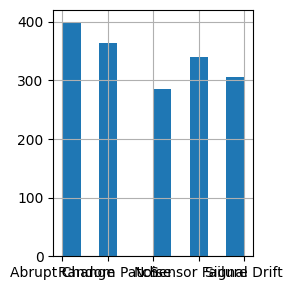

In [31]:
df_out['dominant_abnormal'].hist(figsize=(3,3))
plt.tight_layout()
plt.show()

<Axes: >

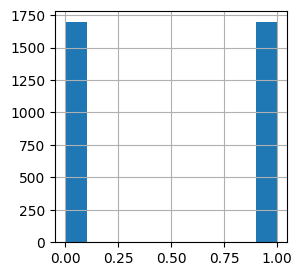

In [32]:
#Với mỗi ảnh thường, tạo một ảnh bất thường
df_out['is_normal'].hist(figsize=(3,3))

In [33]:
import shutil

# Nén toàn bộ thư mục /kaggle/working thành file working.zip
shutil.make_archive('/kaggle/working/working', 'zip', '/kaggle/working')

'/kaggle/working/working.zip'